## 0. Preparação do ambiente

Importe as bibliotecas principais e configure opções de visualização.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_rows', 10)
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 10)

print('Bibliotecas carregadas.')

Bibliotecas carregadas.


## 1) Leitura e Escrita

Nesta etapa, carregamos a base `base_credito.csv` e apresentamos os primeiros registros.

In [2]:
CAMINHO_NO_DRIVE = '/content/drive/MyDrive/base_credito.csv'

try:
    from google.colab import drive
    drive.mount('/content/drive')
    df = pd.read_csv(CAMINHO_NO_DRIVE)
except ImportError:
    # lê o arquivo da pasta local
    df = pd.read_csv('base_credito.csv')

display(df.head())


,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
0,47,11522.48,634,76.73,35229.74
1,40,13157.86,589,90.83,44177.99
2,38,7296.76,721,77.94,33868.30
3,42,11193.87,710,94.09,52289.28
4,43,12798.60,576,73.83,38663.54


In [3]:
print('Dimensões da base:', df.shape)
print('Quantidade de linhas:', len(df))
print('Quantidade de colunas:', len(df.columns))

Dimensões da base: (50000, 5)
Quantidade de linhas: 50000
Quantidade de colunas: 5


## 2) Tratamentos de Dados

Antes de construir o modelo, verificamos os tipos das variáveis, valores ausentes e registros duplicados.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   idade                 50000 non-null  int64  
 1   renda_mensal          50000 non-null  float64
 2   score_credito         50000 non-null  int64  
 3   historico_pagamentos  50000 non-null  float64
 4   valor_emprestimo      50000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 1.9 MB


**Tipos de dados presentes na base:** pela saída do `df.info()` acima, todas as 5 colunas são numéricas e não há valores ausentes. `idade` e `score_credito` são números inteiros (`int64`), enquanto `renda_mensal`, `historico_pagamentos` e `valor_emprestimo` são números decimais (`float64`). Não há colunas de texto (`object`), o que facilita o uso direto dessas variáveis no modelo de regressão.

In [5]:
print('Valores ausentes por coluna:')
display(df.isna().sum().to_frame('quantidade'))

print('Registros duplicados:', df.duplicated().sum())

Valores ausentes por coluna:
Registros duplicados: 0


,quantidade
idade,0
renda_mensal,0
score_credito,0
historico_pagamentos,0
valor_emprestimo,0


In [6]:
print('Estatísticas descritivas:')
display(df.describe())

Estatísticas descritivas:


,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,40.08028,7542.184144,649.581780,81.836888,31736.158491
std,10.77612,4524.255313,84.648363,11.209708,14456.325322
min,18.00000,1500.000000,300.000000,16.210000,1000.000000
25%,33.00000,4463.347500,592.000000,75.160000,22018.212500
50%,40.00000,6452.295000,650.000000,83.720000,29039.420000
75%,47.00000,9395.700000,707.000000,90.330000,38275.932500
max,70.00000,50000.000000,850.000000,100.000000,150000.000000


### Variáveis utilizadas

As variáveis de entrada do modelo são `idade`, `renda_mensal`, `score_credito` e `historico_pagamentos`. A variável que será prevista é `valor_emprestimo`.

In [7]:
variaveis_entrada = ['idade', 'renda_mensal', 'score_credito', 'historico_pagamentos']
variavel_alvo = 'valor_emprestimo'

print('Variáveis de entrada:', variaveis_entrada)
print('Variável-alvo:', variavel_alvo)

Variáveis de entrada: ['idade', 'renda_mensal', 'score_credito', 'historico_pagamentos']
Variável-alvo: valor_emprestimo


### Significado de cada variável

- **idade**: idade do cliente, em anos. Pode se relacionar com estabilidade financeira e histórico de vida profissional.
- **renda_mensal**: renda mensal declarada pelo cliente, em reais. Indica a capacidade de pagamento e costuma ser um dos fatores mais determinantes na análise de crédito.
- **score_credito**: pontuação de crédito do cliente (quanto maior, menor o risco percebido pela instituição financeira).
- **historico_pagamentos**: representa a quantidade de pagamentos em dia do cliente, em uma escala de 0 a 100 (percentual). Quanto maior o valor, melhor o histórico de pagamentos do cliente e, em geral, menor o risco de crédito associado a ele.
- **valor_emprestimo** (variável-alvo): valor do empréstimo aprovado para o cliente, em reais. É a variável que o modelo deve aprender a prever.


## 3) Análise de Dados

Vamos observar a relação entre as variáveis da base e o valor do empréstimo.

In [8]:
print('Matriz de correlação:')
display(df.corr(numeric_only=True).round(3))

Matriz de correlação:


,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
idade,1.000,0.001,0.000,-0.000,0.041
renda_mensal,0.001,1.000,0.001,0.001,0.887
score_credito,0.000,0.001,1.000,0.000,0.358
historico_pagamentos,-0.000,0.001,0.000,1.000,0.077
valor_emprestimo,0.041,0.887,0.358,0.077,1.000


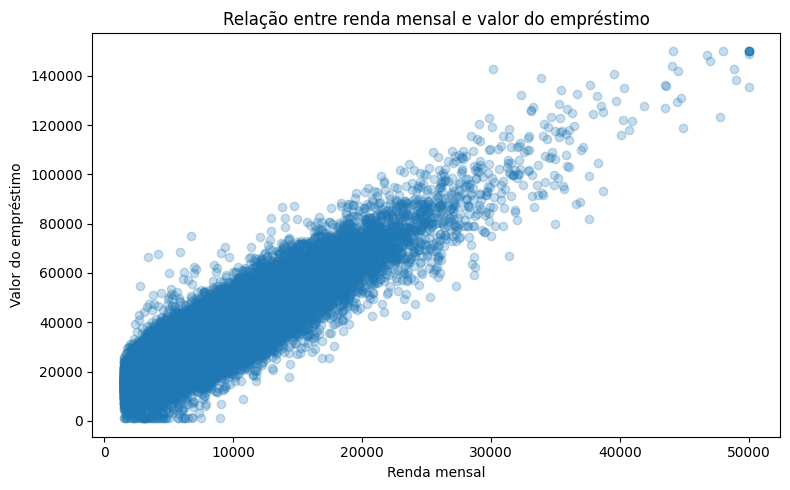

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df['renda_mensal'], df['valor_emprestimo'], alpha=0.25)
plt.xlabel('Renda mensal')
plt.ylabel('Valor do empréstimo')
plt.title('Relação entre renda mensal e valor do empréstimo')
plt.tight_layout()
plt.show()

## Distribuição da variável-alvo

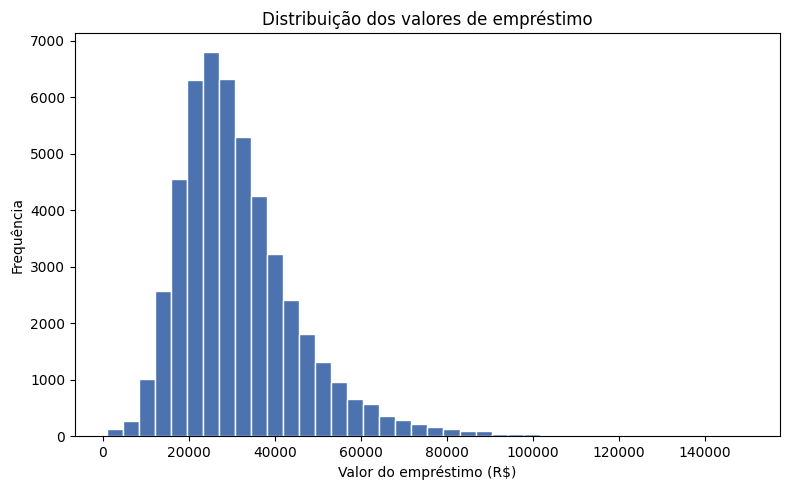

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df['valor_emprestimo'], bins=40, color='#4C72B0', edgecolor='white')
plt.xlabel('Valor do empréstimo (R$)')
plt.ylabel('Frequência')
plt.title('Distribuição dos valores de empréstimo')
plt.tight_layout()
plt.show()


**Interpretação:** a distribuição do valor do empréstimo é assimétrica à direita (cauda longa), ou seja, a maioria dos empréstimos concentra-se em valores mais baixos/medianos, havendo uma quantidade menor de empréstimos com valores bem mais altos.

### Mapa de calor da correlação

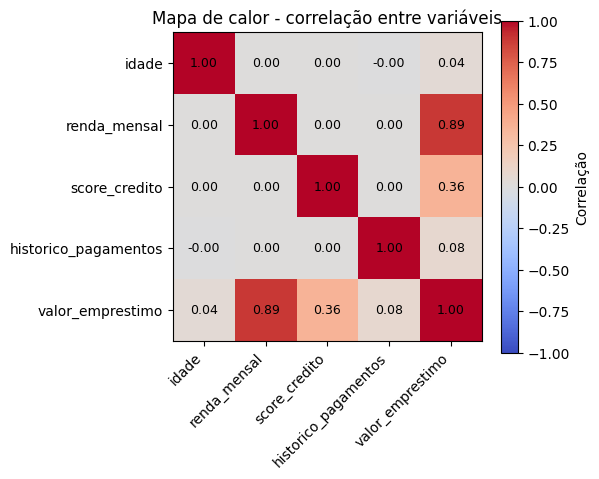

In [11]:
plt.figure(figsize=(6, 5))
corr = df.corr(numeric_only=True)
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlação')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
plt.title('Mapa de calor - correlação entre variáveis')
plt.tight_layout()
plt.show()


**Interpretação:** observa-se uma relação positiva entre a renda mensal e o valor do empréstimo. Em geral, clientes com renda maior apresentam valores de empréstimo maiores. A dispersão dos pontos mostra que a renda, sozinha, não determina completamente o valor aprovado, justificando o uso das demais características no modelo.

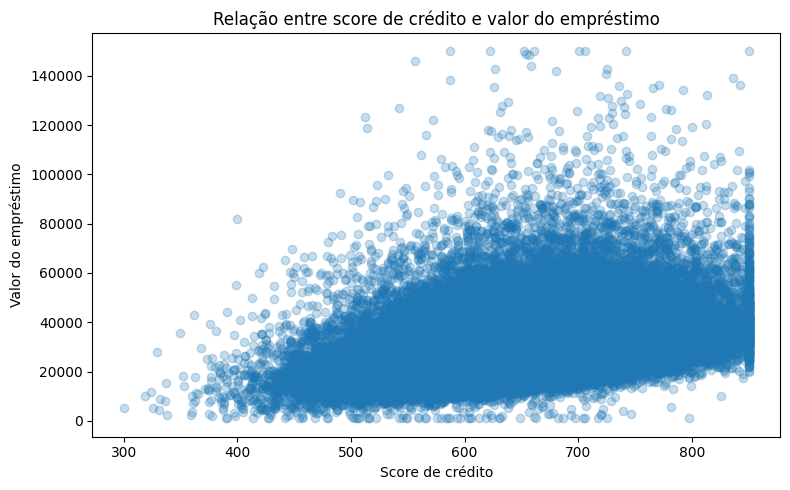

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(df['score_credito'], df['valor_emprestimo'], alpha=0.25)
plt.xlabel('Score de crédito')
plt.ylabel('Valor do empréstimo')
plt.title('Relação entre score de crédito e valor do empréstimo')
plt.tight_layout()
plt.show()

**Interpretação:** existe uma relação positiva mais moderada entre score de crédito e valor do empréstimo. Isso indica que o score também contém informação útil para a previsão, embora sua relação com o valor aprovado seja menos forte que a observada para a renda mensal.

### Relação entre idade e valor do empréstimo

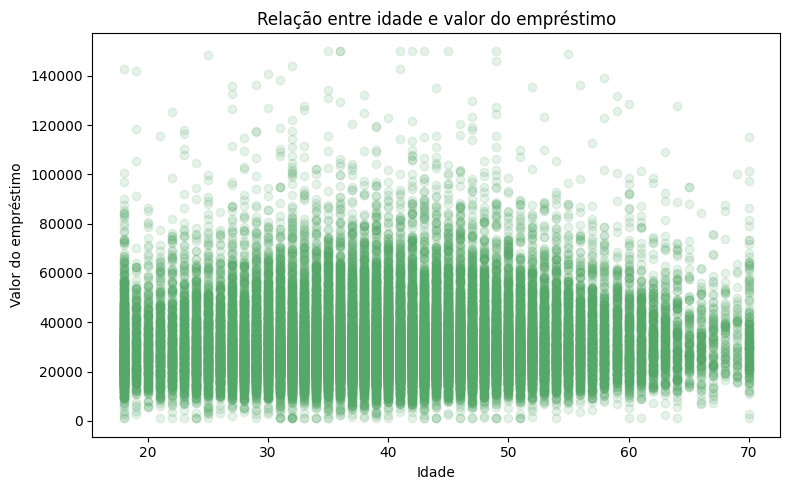

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(df['idade'], df['valor_emprestimo'], alpha=0.15, color='#55A868')
plt.xlabel('Idade')
plt.ylabel('Valor do empréstimo')
plt.title('Relação entre idade e valor do empréstimo')
plt.tight_layout()
plt.show()


**Interpretação:** diferentemente da renda e do score, a idade apresenta uma relação bem fraca com o valor do empréstimo (correlação próxima de zero), sugerindo que, sozinha, ela tem pouco poder preditivo nesta base.

## 4) Preparação dos dados

Separaremos as características (`X`) da variável que queremos prever (`y`) e depois dividiremos os dados em treinamento e teste. Será utilizada a proporção de 80% para treinamento e 20% para teste.

In [14]:
X = df[variaveis_entrada]
y = df[variavel_alvo]

display(X.head())
display(y.head())

,idade,renda_mensal,score_credito,historico_pagamentos
0,47,11522.48,634,76.73
1,40,13157.86,589,90.83
2,38,7296.76,721,77.94
3,42,11193.87,710,94.09
4,43,12798.60,576,73.83


0    35229.74
1    44177.99
2    33868.30
3    52289.28
4    38663.54
Name: valor_emprestimo, dtype: float64

In [15]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print('Treinamento:', X_treino.shape[0], 'registros')
print('Teste:', X_teste.shape[0], 'registros')

Treinamento: 40000 registros
Teste: 10000 registros


## 5) Modelo de Regressão

Será utilizada a **Regressão Linear**, um algoritmo de regressão que relaciona as variáveis de entrada ao valor do empréstimo.

In [16]:
modelo = LinearRegression()
modelo.fit(X_treino, y_treino)

print('Modelo treinado.')

Modelo treinado.


### Interpretação dos coeficientes

In [17]:
coeficientes = pd.DataFrame({
    'variavel': variaveis_entrada,
    'coeficiente': modelo.coef_
}).sort_values('coeficiente', key=abs, ascending=False)

print(f'Intercepto: {modelo.intercept_:.2f}')
display(coeficientes)


Intercepto: -39439.69


,variavel,coeficiente
3,historico_pagamentos,98.907289
2,score_credito,60.890564
0,idade,54.706246
1,renda_mensal,2.828448


**Interpretação:** o coeficiente indica o quanto o valor previsto do empréstimo muda, em média, para cada unidade de aumento na variável (mantendo as demais constantes). Coeficientes com maior valor absoluto — normalmente `renda_mensal` e `score_credito` — são os que mais influenciam a previsão, o que é coerente com a análise de correlação feita anteriormente.

In [18]:
y_pred = modelo.predict(X_teste)

display(pd.DataFrame({
    'valor_real': y_teste.values[:10],
    'valor_previsto': y_pred[:10]
}))

,valor_real,valor_previsto
0,22268.46,14806.335657
1,27457.59,29512.492879
2,25451.04,25840.735547
3,23890.67,21077.522905
4,27754.95,27919.314046
5,12544.92,14530.910394
6,28759.01,27385.966936
7,46454.49,41011.609092
8,43199.01,36525.087756
9,34051.39,35786.960945


## 6) Avaliação do modelo

Serão utilizadas três métricas: MAE, RMSE e R².

In [19]:
mae = mean_absolute_error(y_teste, y_pred)
rmse = np.sqrt(mean_squared_error(y_teste, y_pred))
r2 = r2_score(y_teste, y_pred)

print(f'MAE: R$ {mae:,.2f}')
print(f'RMSE: R$ {rmse:,.2f}')
print(f'R²: {r2:.4f}')

MAE: R$ 2,985.94
RMSE: R$ 4,014.17
R²: 0.9223


**Interpretação:** o MAE indica que, em média, as previsões se afastam dos valores reais em aproximadamente R$ 2.985,94. O RMSE foi de aproximadamente R$ 4.014,17, dando maior peso aos erros maiores. O R² de 0,9223 indica que o modelo explica aproximadamente 92,23% da variação observada no valor dos empréstimos na amostra de teste.

### Análise dos resíduos

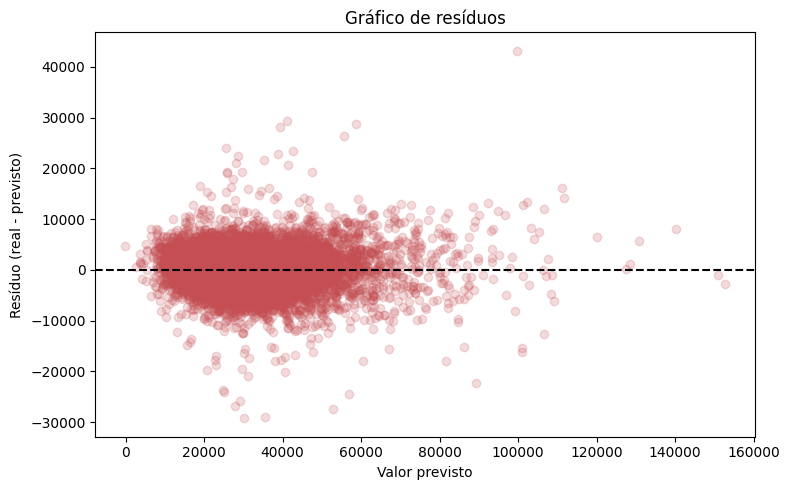

In [20]:
residuos = y_teste.values - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuos, alpha=0.2, color='#C44E52')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Valor previsto')
plt.ylabel('Resíduo (real - previsto)')
plt.title('Gráfico de resíduos')
plt.tight_layout()
plt.show()


**Interpretação:** os resíduos se distribuem de forma razoavelmente aleatória em torno de zero, sem um padrão claro (como uma curva ou um funil muito pronunciado). Isso é um bom sinal, pois indica que o modelo não está sistematicamente errando para valores específicos — embora a dispersão aumente um pouco para empréstimos maiores, mostrando que a variância do erro não é totalmente constante.

## 7) Comparação entre valores reais e previstos

A tabela apresenta exemplos da comparação entre os valores reais e os valores estimados pelo modelo.

In [21]:
comparacao = pd.DataFrame({
    'valor_real': y_teste.values,
    'valor_previsto': y_pred,
    'erro_absoluto': np.abs(y_teste.values - y_pred)
})

display(comparacao.head(10))

,valor_real,valor_previsto,erro_absoluto
0,22268.46,14806.335657,7462.124343
1,27457.59,29512.492879,2054.902879
2,25451.04,25840.735547,389.695547
3,23890.67,21077.522905,2813.147095
4,27754.95,27919.314046,164.364046
5,12544.92,14530.910394,1985.990394
6,28759.01,27385.966936,1373.043064
7,46454.49,41011.609092,5442.880908
8,43199.01,36525.087756,6673.922244
9,34051.39,35786.960945,1735.570945


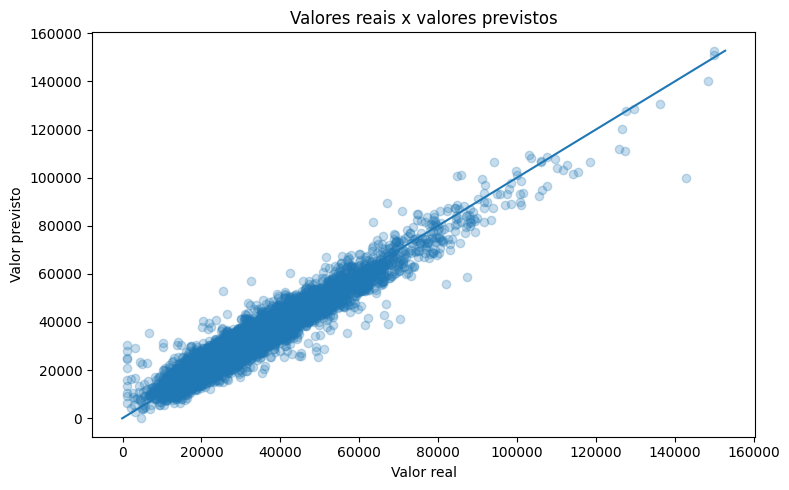

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(y_teste, y_pred, alpha=0.25)

limite_min = min(y_teste.min(), y_pred.min())
limite_max = max(y_teste.max(), y_pred.max())
plt.plot([limite_min, limite_max], [limite_min, limite_max])

plt.xlabel('Valor real')
plt.ylabel('Valor previsto')
plt.title('Valores reais x valores previstos')
plt.tight_layout()
plt.show()

**Interpretação:** os pontos ficam, em grande parte, próximos da linha de referência, indicando que as previsões acompanham os valores reais. Ainda existem alguns erros mais elevados, principalmente em determinados empréstimos, portanto o modelo não reproduz perfeitamente todos os casos.

## 8) Fazer uma previsão

Agora será criado um novo cliente com características escolhidas para a atividade.

In [23]:
novo_cliente = pd.DataFrame({
    'idade': [35],
    'renda_mensal': [6000],
    'score_credito': [750],
    'historico_pagamentos': [90]
})

display(novo_cliente)

,idade,renda_mensal,score_credito,historico_pagamentos
0,35,6000,750,90


In [24]:
previsao = modelo.predict(novo_cliente)[0]
print(f'Valor de empréstimo previsto: R$ {previsao:,.2f}')

Valor de empréstimo previsto: R$ 34,015.29


**Interpretação:** para o cliente criado, com renda mensal de R$ 6.000, score de crédito 750 e histórico de pagamentos de 90, o modelo estima um empréstimo de aproximadamente **R$ 34.015,29**. Esse valor é uma estimativa baseada nos padrões encontrados na base histórica.

## 9) Conclusão

A Regressão Linear apresentou R² de 0,9223 no conjunto de teste, enquanto o MAE foi de R$ 2.985,94 e o RMSE de R$ 4.014,17. Esses resultados mostram que o modelo consegue explicar uma parcela elevada da variação dos valores de empréstimo presentes na base e produzir previsões relativamente próximas dos valores observados.

Como limitações, o modelo assume uma relação linear entre as características utilizadas e o valor do empréstimo. Além disso, a previsão depende exclusivamente das variáveis disponíveis na base. Outros fatores que poderiam influenciar a decisão de crédito, mas que não estejam registrados nos dados, não são considerados.